# Supplier cybersecurity incidents — starting point



In [54]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, confusion_matrix)
from sklearn.model_selection import train_test_split

In [44]:
import sklearn
sklearn.__version__

'1.6.1'

In [4]:
random_variable = 20261026

In [5]:
folder_path = "https://raw.github.com/jan-source/ppa_erp_student/main/case_1_supplier/"

### Helper Functions

In [6]:
def evaluate_model(y_true, y_pred, print_results=True):
    cnf_matrix = confusion_matrix(y_true, y_pred, labels=[True, False])
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matrix.T,
                                 display_labels=['cybersecurity incident', 'no cybersecurity incident'])

    # Create a figure and plot
    if print_results:
        fig, ax = plt.subplots(figsize=(8, 6))
        disp.plot(ax=ax, cmap='Blues')
        plt.xlabel('Actual Condition')  # This will now be on the x-axis
        plt.ylabel('Predicted Condition')  # This will now be on the y-axis
        plt.title('Confusion Matrix for Cybersecurity Incidents')
        plt.show()

    # Add precision, recall, and F1-score
    accuracy = round(accuracy_score(y_true, y_pred), 4)
    precision = round(precision_score(y_true, y_pred), 4)
    recall = round(recall_score(y_true, y_pred), 4)
    f1 = round(f1_score(y_true, y_pred), 4)
    if print_results:
        print(f'Accuracy: {accuracy:.2f}')
        print(f'Precision: {precision:.2f}')
        print(f'Recall: {recall:.2f}')
        print(f'F1-score: {f1:.2f}')

    return accuracy, precision, recall, f1


## 1. Load and merge the data

In [7]:
master = pd.read_excel(folder_path + 'supplier_master.xlsx')
assessment = pd.read_excel(folder_path + 'cybersecurity_assessment.xlsx')

In [8]:
master.head()

,supplier_id,supplier_name,industry,country,employees,annual_revenue_m_eur,years_as_supplier,business_criticality,access_level,sensitive_data_access
0,SUP-0001,Prime Digital 0001,Professional services,Germany,417,48.9,4,High,Portal only,True
1,SUP-0002,Evergreen Works 0002,Logistics,Poland,20,3.6,9,Medium,No access,False
2,SUP-0003,Blue Networks 0003,Industrial manufacturing,Mexico,276,43.2,8,Medium,Portal only,False
3,SUP-0004,Central Industries 0004,Electronics,Poland,103,22.0,2,Low,Portal only,False
4,SUP-0005,Global Supply 0005,IT services,Germany,809,68.4,5,Medium,Business systems,True


### Kombinieren der Daten

In [9]:
data = pd.merge(master, assessment, on='supplier_id', how='inner')

**Share of Suppliers with Cybersecurity Incidence**

In [10]:
data['cybersecurity_incident_past_12m'].mean()

np.float64(0.20333333333333334)

In [11]:
data.dtypes

,0
supplier_id,object
supplier_name,object
industry,object
country,object
employees,int64
annual_revenue_m_eur,float64
years_as_supplier,int64
business_criticality,object
access_level,object
sensitive_data_access,bool


Delete all rows which at least one empty value

In [12]:
complete_data = data.dropna(axis=0).copy()

In [13]:
complete_data.shape

(1024, 22)

In [14]:
data.shape

(1200, 22)

Comparison of cybersecurity incidences across different variables

In [15]:
complete_data.groupby("industry")["cybersecurity_incident_past_12m"].mean()

,cybersecurity_incident_past_12m
industry,
Cloud and software,0.192308
Electronics,0.186441
IT services,0.260684
Industrial manufacturing,0.202454
Logistics,0.190789
Professional services,0.183099


In [16]:
complete_data.groupby("country")["cybersecurity_incident_past_12m"].mean()

,cybersecurity_incident_past_12m
country,
Austria,0.213333
France,0.220183
Germany,0.232877
India,0.140496
Mexico,0.181818
Netherlands,0.204545
Poland,0.198113
USA,0.217949


In [17]:
complete_data.groupby("access_level")["cybersecurity_incident_past_12m"].mean()

,cybersecurity_incident_past_12m
access_level,
Business systems,0.229102
No access,0.176101
Portal only,0.171021
Privileged,0.314050


#### Define Features

In [18]:
categorical_columns = ["industry", "country", "business_criticality", "access_level"]

In [19]:
features_numeric = [col for col in complete_data.columns
                    if complete_data[col].dtype != "object"
                      and col != "cybersecurity_incident_past_12m"]

In [20]:
features_numeric

['employees',
 'annual_revenue_m_eur',
 'years_as_supplier',
 'sensitive_data_access',
 'external_attack_surface_score',
 'security_rating',
 'average_patch_delay_days',
 'mfa_coverage_pct',
 'security_training_coverage_pct',
 'prior_incidents_3y',
 'fourth_party_dependency_count',
 'iso27001_certified',
 'incident_response_plan_tested',
 'cyber_insurance',
 'security_questionnaire_score']

### Generate Dummy Variables for Categorical Features

In [21]:
features_with_dummies = features_numeric.copy()

In [22]:
for c in categorical_columns:
  dummies = pd.get_dummies(complete_data[c], prefix=c, drop_first=True)

  features_with_dummies = features_with_dummies + list(dummies.columns)

  complete_data = pd.concat([complete_data, dummies], axis=1)

In [23]:
len(features_with_dummies)

33

In [24]:
features_with_dummies

['employees',
 'annual_revenue_m_eur',
 'years_as_supplier',
 'sensitive_data_access',
 'external_attack_surface_score',
 'security_rating',
 'average_patch_delay_days',
 'mfa_coverage_pct',
 'security_training_coverage_pct',
 'prior_incidents_3y',
 'fourth_party_dependency_count',
 'iso27001_certified',
 'incident_response_plan_tested',
 'cyber_insurance',
 'security_questionnaire_score',
 'industry_Electronics',
 'industry_IT services',
 'industry_Industrial manufacturing',
 'industry_Logistics',
 'industry_Professional services',
 'country_France',
 'country_Germany',
 'country_India',
 'country_Mexico',
 'country_Netherlands',
 'country_Poland',
 'country_USA',
 'business_criticality_High',
 'business_criticality_Low',
 'business_criticality_Medium',
 'access_level_No access',
 'access_level_Portal only',
 'access_level_Privileged']

### Calculate Models

In [25]:
log_reg_simple = LogisticRegression(random_state=random_variable)

In [26]:
log_reg_simple.fit(complete_data[features_numeric], complete_data['cybersecurity_incident_past_12m'])

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(random_state=20261026)

In [27]:
pd.DataFrame({"feature": features_numeric, "coefficients": log_reg_simple.coef_[0] })

,feature,coefficients
0,employees,0.000125
1,annual_revenue_m_eur,-0.001692
2,years_as_supplier,0.026069
3,sensitive_data_access,0.210885
4,external_attack_surface_score,0.009747
5,security_rating,-0.029000
6,average_patch_delay_days,0.016780
7,mfa_coverage_pct,-0.012872
8,security_training_coverage_pct,-0.003510
9,prior_incidents_3y,0.350568


In [28]:
predictions_log_only_numeric = log_reg_simple.predict(complete_data[features_numeric])

In [43]:
len(features_numeric)

15

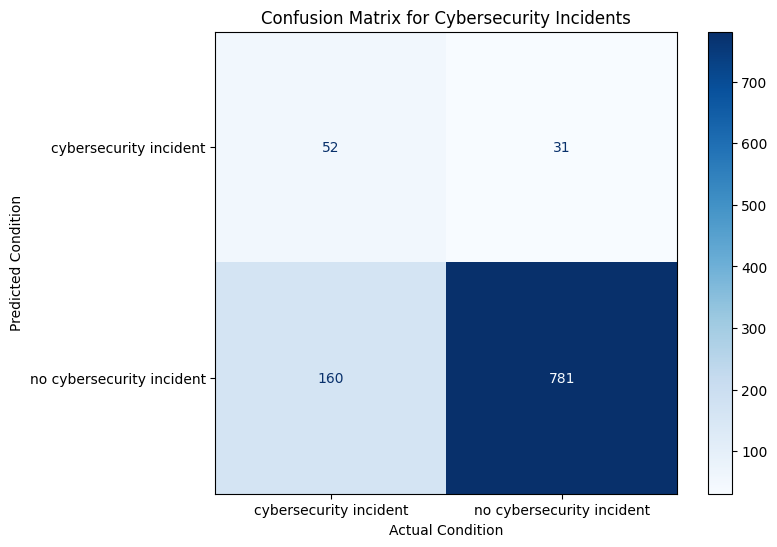

Accuracy: 0.81
Precision: 0.63
Recall: 0.25
F1-score: 0.35


(0.8135, 0.6265, 0.2453, 0.3525)

In [29]:
evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_log_only_numeric)

### Adding categorical features

In [30]:
features_with_dummies

['employees',
 'annual_revenue_m_eur',
 'years_as_supplier',
 'sensitive_data_access',
 'external_attack_surface_score',
 'security_rating',
 'average_patch_delay_days',
 'mfa_coverage_pct',
 'security_training_coverage_pct',
 'prior_incidents_3y',
 'fourth_party_dependency_count',
 'iso27001_certified',
 'incident_response_plan_tested',
 'cyber_insurance',
 'security_questionnaire_score',
 'industry_Electronics',
 'industry_IT services',
 'industry_Industrial manufacturing',
 'industry_Logistics',
 'industry_Professional services',
 'country_France',
 'country_Germany',
 'country_India',
 'country_Mexico',
 'country_Netherlands',
 'country_Poland',
 'country_USA',
 'business_criticality_High',
 'business_criticality_Low',
 'business_criticality_Medium',
 'access_level_No access',
 'access_level_Portal only',
 'access_level_Privileged']

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


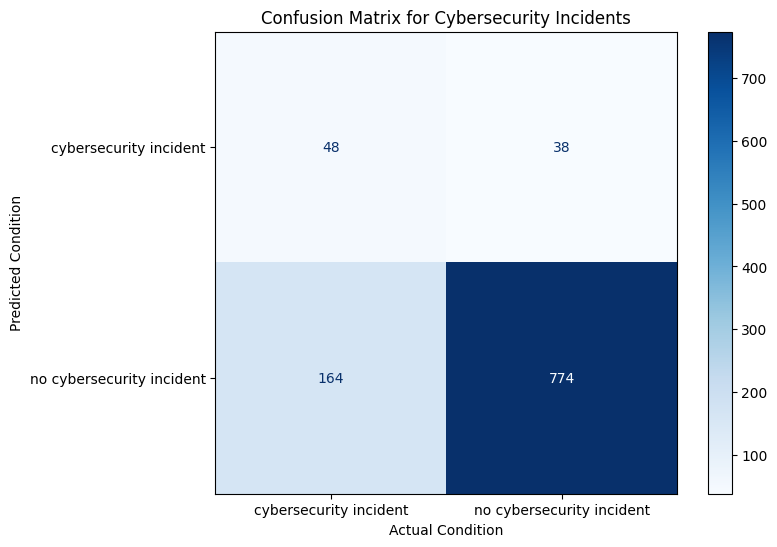

Accuracy: 0.80
Precision: 0.56
Recall: 0.23
F1-score: 0.32


(0.8027, 0.5581, 0.2264, 0.3221)

In [31]:
log_reg_w_dummies = LogisticRegression(random_state=random_variable)

log_reg_w_dummies.fit(complete_data[features_with_dummies], complete_data['cybersecurity_incident_past_12m'])

predictions_log_w_dummies = log_reg_w_dummies.predict(complete_data[features_with_dummies])

evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_log_w_dummies)

In [32]:
complete_data['country'].unique()

array(['Germany', 'Poland', 'Mexico', 'Netherlands', 'USA', 'France',
       'India', 'Austria'], dtype=object)

In [33]:
pd.DataFrame({"feature": features_with_dummies, "coefficients": log_reg_w_dummies.coef_[0] })

,feature,coefficients
0,employees,0.000119
1,annual_revenue_m_eur,-0.001568
2,years_as_supplier,0.111362
3,sensitive_data_access,0.082154
4,external_attack_surface_score,0.011655
5,security_rating,-0.035082
6,average_patch_delay_days,0.015781
7,mfa_coverage_pct,-0.005782
8,security_training_coverage_pct,-0.003346
9,prior_incidents_3y,0.152561


### Decision Tree

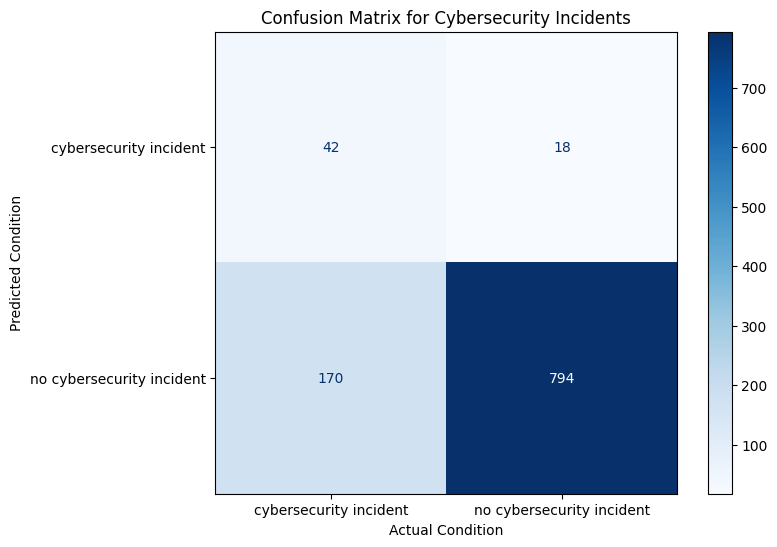

Accuracy: 0.82
Precision: 0.70
Recall: 0.20
F1-score: 0.31


(0.8164, 0.7, 0.1981, 0.3088)

In [34]:
decision_tree_numeric_features = DecisionTreeClassifier(random_state=random_variable, max_depth=3)

decision_tree_numeric_features.fit(complete_data[features_numeric], complete_data['cybersecurity_incident_past_12m'])

predictions_tree_numeric_features = decision_tree_numeric_features.predict(complete_data[features_numeric])

evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_tree_numeric_features)

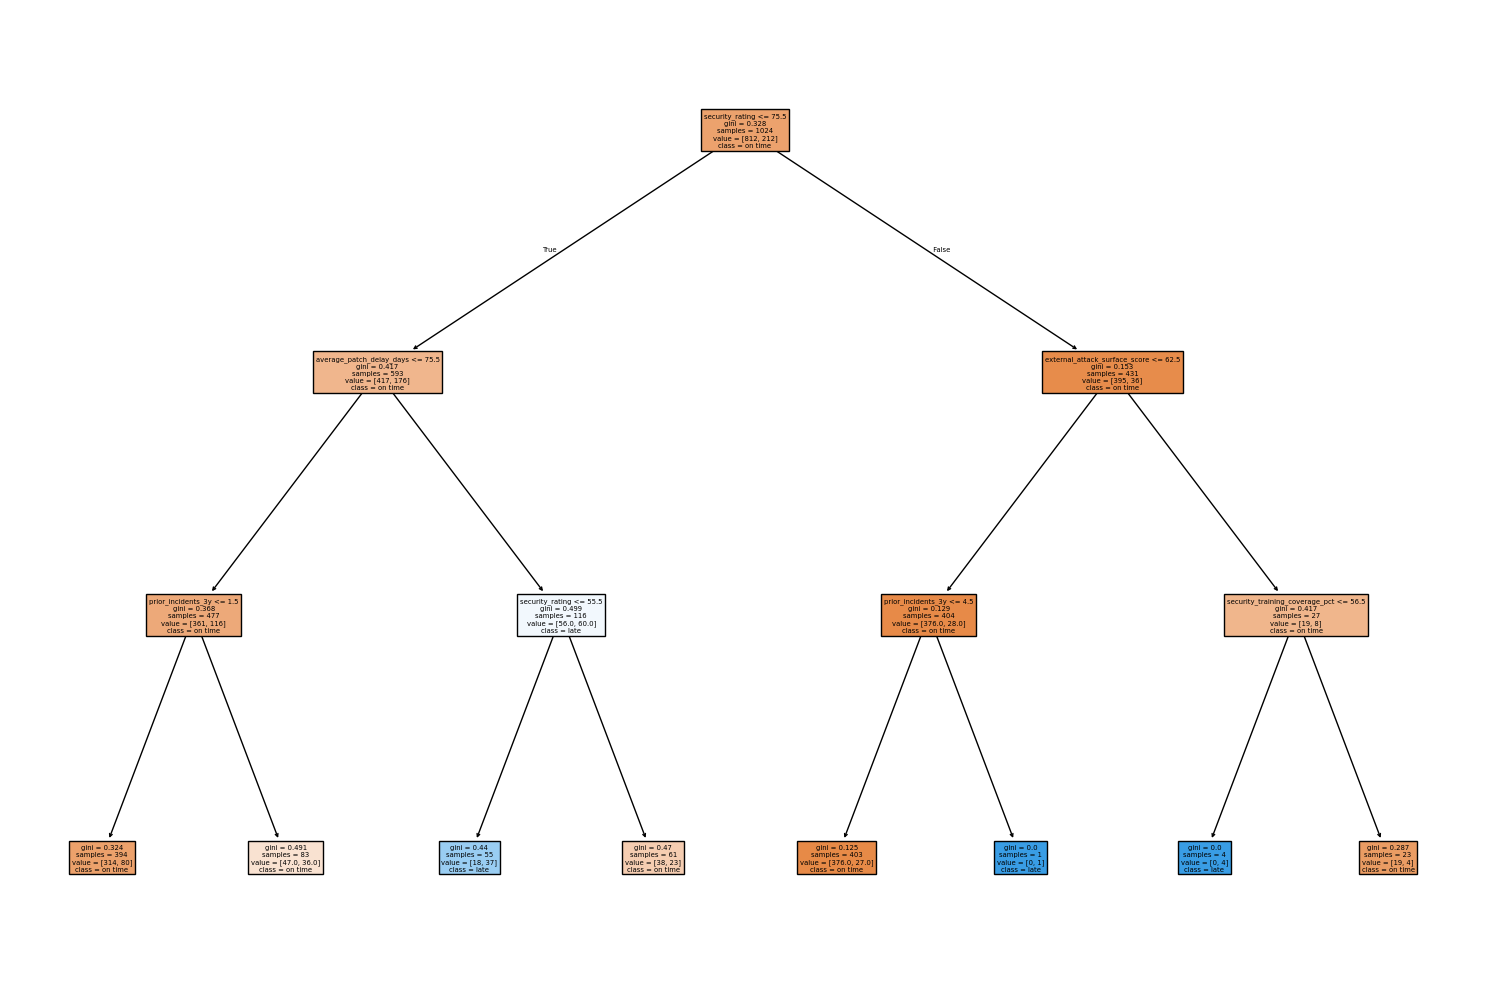

In [35]:


plt.figure(figsize=(15, 10))
tree.plot_tree(
        decision_tree_numeric_features,
        feature_names=features_numeric,
        class_names=['on time', 'late'],
        filled=True
        )
plt.tight_layout()

plt.show()



In [37]:
results_tree = []
for i in range(2,20):
    decision_tree_w_supplier_ = DecisionTreeClassifier(random_state=random_variable, max_depth=i)
    decision_tree_w_supplier_.fit(complete_data[features_with_dummies], complete_data['cybersecurity_incident_past_12m'])
    predictions_tree_w_supplier_ = decision_tree_w_supplier_.predict(complete_data[features_with_dummies])
    accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_tree_w_supplier_, print_results=False)
    results_tree.append({'model': f'Max_depth={i}', 'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1': f1})

pd.DataFrame(results_tree)




,model,accuracy,precision,recall,f1
0,Max_depth=2,0.7969,0.5172,0.2830,0.3659
1,Max_depth=3,0.8164,0.7000,0.1981,0.3088
2,Max_depth=4,0.8242,0.7963,0.2028,0.3233
3,Max_depth=5,0.8418,0.7976,0.3160,0.4527
4,Max_depth=6,0.8594,0.8148,0.4151,0.5500
5,Max_depth=7,0.8857,0.8682,0.5283,0.6569
6,Max_depth=8,0.9111,0.9116,0.6321,0.7465
7,Max_depth=9,0.9307,0.9669,0.6887,0.8044
8,Max_depth=10,0.9570,0.9615,0.8255,0.8883
9,Max_depth=11,0.9678,0.9686,0.8726,0.9181


### Split in train and test dataset

In [40]:
X_train, X_test, y_train, y_test =  train_test_split(
    complete_data[features_with_dummies],
    complete_data["cybersecurity_incident_past_12m"],
    test_size=0.2,
    random_state=random_variable
    )

In [49]:

tree_depths = range(2,20)
results_tree = []

for i in tree_depths:
    decision_tree_w_supplier_ = DecisionTreeClassifier(random_state=random_variable, max_depth=i)

    # Train Model in Training Data
    decision_tree_w_supplier_.fit(X_train, y_train)

    # Calculate Predictions on Test and Training Data
    predictions_tree_w_supplier_test = decision_tree_w_supplier_.predict(X_test)
    predictions_tree_w_supplier_train = decision_tree_w_supplier_.predict(X_train)

    # Evaluate on Train Dataset
    accuracy_train, precision_train, recall_train, f1_train = evaluate_model(
        y_train, predictions_tree_w_supplier_train,
                     print_results=False)

    # Evaluate on Test Dataset
    accuracy_test, precision_test, recall_test, f1_test = evaluate_model(
        y_test, predictions_tree_w_supplier_test,
                     print_results=False)


    # Save Measures for Each Tree
    results_tree.append({
        'model': f'Max_depth={i}',
        'accuracy_train': accuracy_train,
        'precision_train': precision_train,
        'recall_train': recall_train,
        'f1_train': f1_train,
        'accuracy_test': accuracy_test,
        'precision_test': precision_test,
        'recall_test': recall_test,
        'f1_test': f1_test
        })

results_tree_df = pd.DataFrame(results_tree)





In [52]:

results_tree_df

,model,accuracy_train,precision_train,recall_train,f1_train,accuracy_test,precision_test,recall_test,f1_test
0,Max_depth=2,0.7973,1.0000,0.0621,0.1170,0.8244,0.0000,0.0000,0.0000
1,Max_depth=3,0.8144,0.6543,0.2994,0.4109,0.7854,0.2632,0.1429,0.1852
2,Max_depth=4,0.8278,0.7432,0.3107,0.4382,0.8000,0.3125,0.1429,0.1961
3,Max_depth=5,0.8364,0.7263,0.3898,0.5074,0.7756,0.2609,0.1714,0.2069
4,Max_depth=6,0.8730,0.8411,0.5085,0.6338,0.7756,0.2963,0.2286,0.2581
5,Max_depth=7,0.8987,0.9052,0.5932,0.7167,0.7366,0.1935,0.1714,0.1818
6,Max_depth=8,0.9280,0.9470,0.7062,0.8091,0.7561,0.2857,0.2857,0.2857
7,Max_depth=9,0.9487,0.9355,0.8192,0.8735,0.7512,0.2895,0.3143,0.3014
8,Max_depth=10,0.9609,1.0000,0.8192,0.9006,0.7366,0.2683,0.3143,0.2895
9,Max_depth=11,0.9780,0.9818,0.9153,0.9474,0.7122,0.2143,0.2571,0.2338


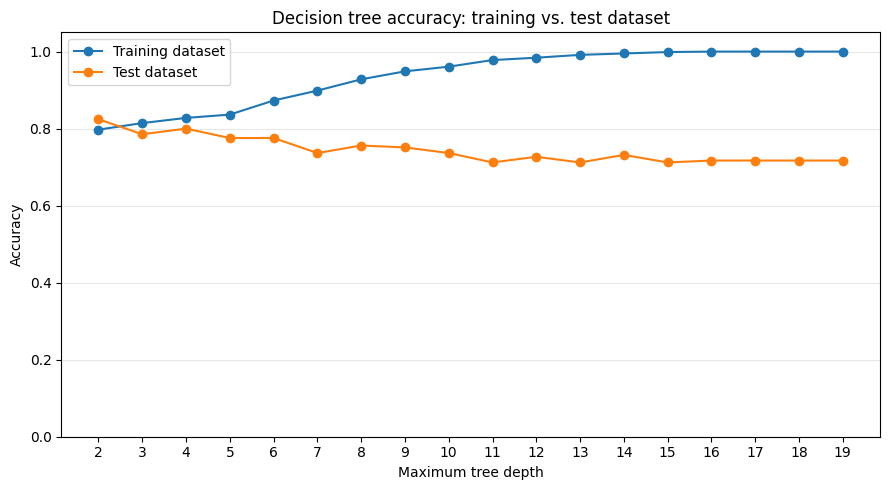

In [50]:


plt.figure(figsize=(9, 5))
plt.plot(tree_depths, results_tree_df['accuracy_train'], marker='o', label='Training dataset')
plt.plot(tree_depths, results_tree_df['accuracy_test'], marker='o', label='Test dataset')
plt.xticks(tree_depths)
plt.ylim(0, 1.05)
plt.xlabel('Maximum tree depth')
plt.ylabel('Accuracy')
plt.title('Decision tree accuracy: training vs. test dataset')
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



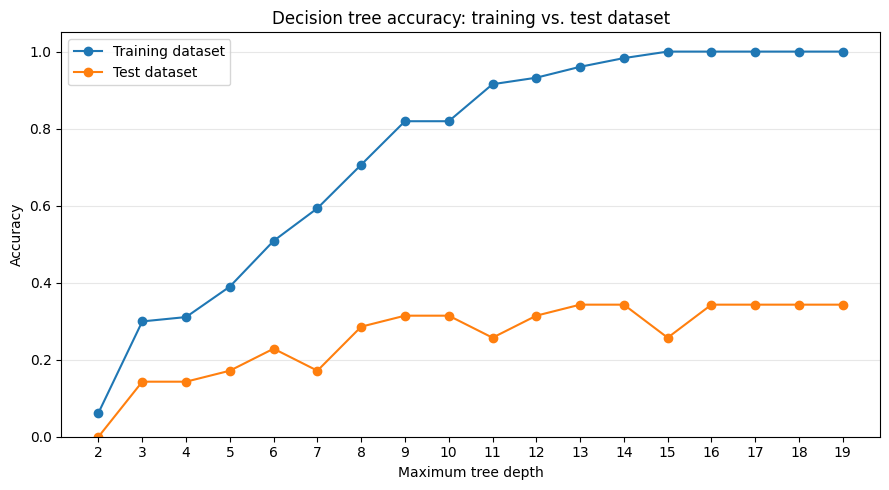

In [51]:


plt.figure(figsize=(9, 5))
plt.plot(tree_depths, results_tree_df['recall_train'], marker='o', label='Training dataset')
plt.plot(tree_depths, results_tree_df['recall_test'], marker='o', label='Test dataset')
plt.xticks(tree_depths)
plt.ylim(0, 1.05)
plt.xlabel('Maximum tree depth')
plt.ylabel('Accuracy')
plt.title('Decision tree accuracy: training vs. test dataset')
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



### Compare to logistic Regression

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


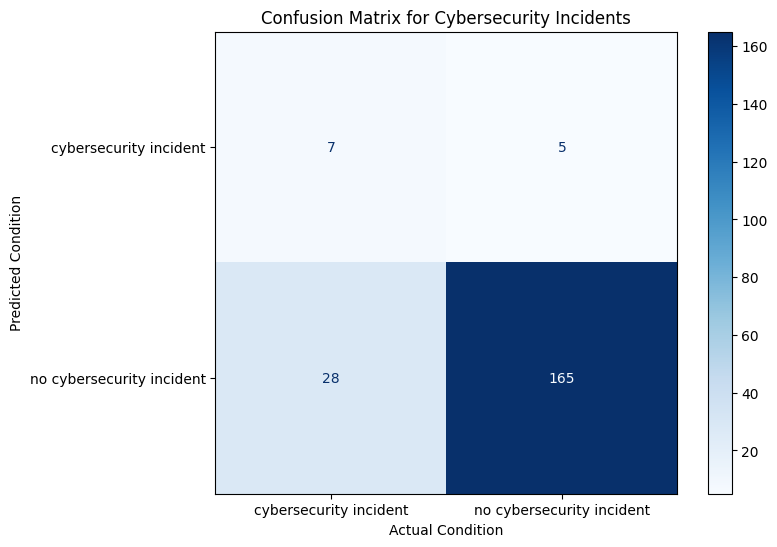

Accuracy: 0.84
Precision: 0.58
Recall: 0.20
F1-score: 0.30


(0.839, 0.5833, 0.2, 0.2979)

In [53]:
log_reg_w_dummies = LogisticRegression(random_state=random_variable)

log_reg_w_dummies.fit(X_train, y_train)

predictions_log_w_dummies = log_reg_w_dummies.predict(X_test)

evaluate_model(y_test, predictions_log_w_dummies)

### Random Forest

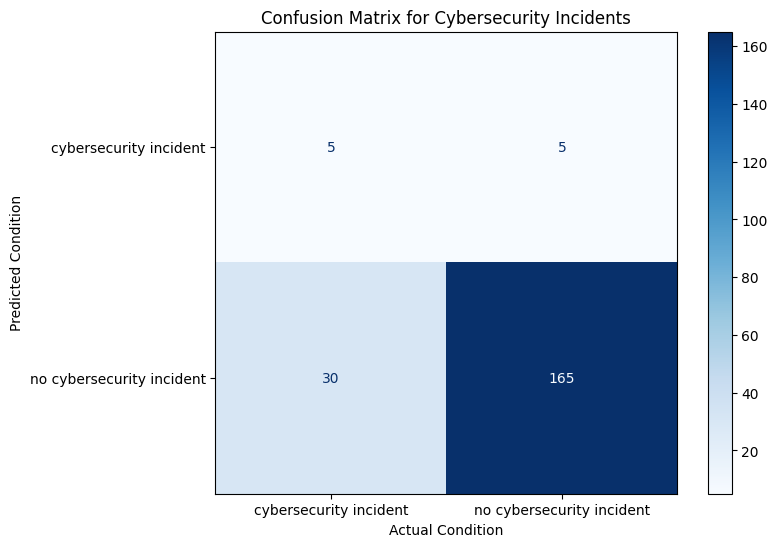

Accuracy: 0.83
Precision: 0.50
Recall: 0.14
F1-score: 0.22


(0.8293, 0.5, 0.1429, 0.2222)

In [68]:

rf = RandomForestClassifier(random_state=random_variable,
                            max_depth=6,
                            n_estimators=500,
                            max_features=15
                            )

rf.fit(X_train, y_train)

predictions_rf_w_dummies = rf.predict(X_test)

evaluate_model(y_test, predictions_rf_w_dummies)




In [65]:
first_rf_tree = rf.estimators_[0]
second_rf_tree = rf.estimators_[1]

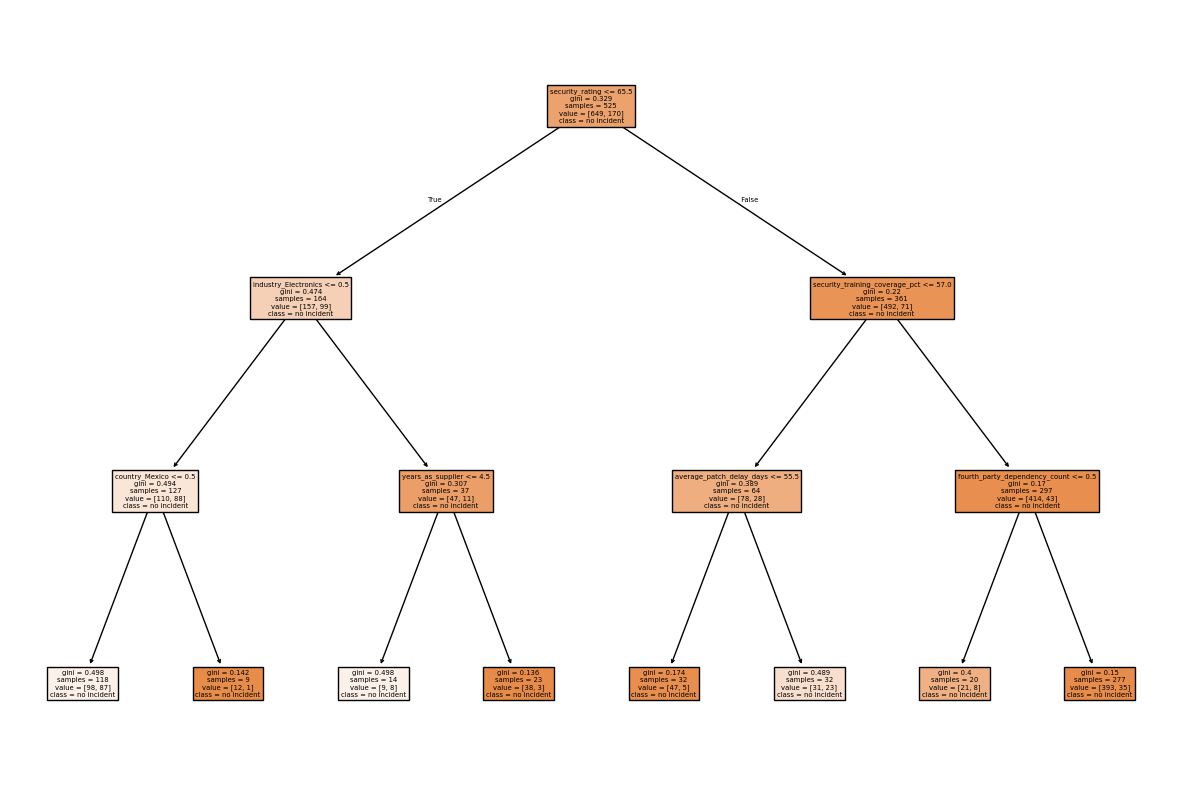

In [62]:
plt.figure(figsize=(15,10))
tree.plot_tree(
        first_rf_tree,
        feature_names=features_with_dummies,
        class_names=['no incident', 'incident'],
        filled=True
        )
plt.show()

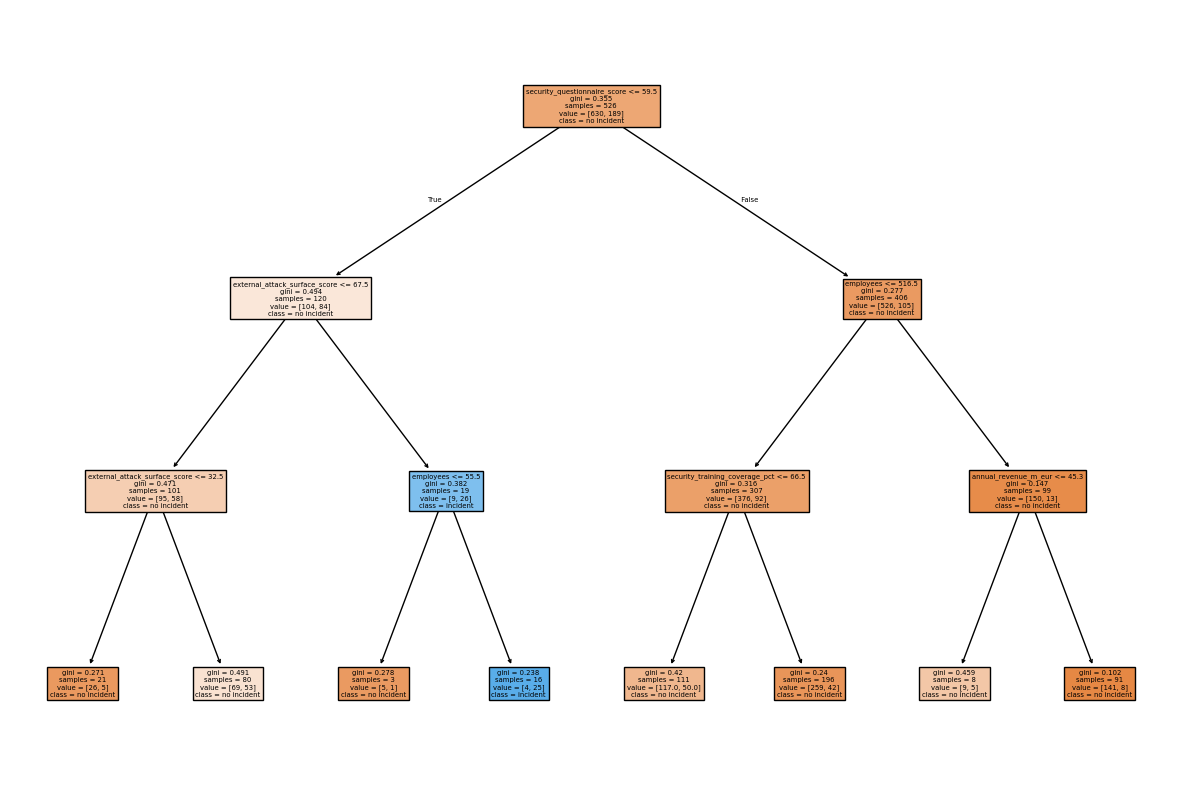

In [63]:
plt.figure(figsize=(15,10))
tree.plot_tree(
        second_rf_tree,
        feature_names=features_with_dummies,
        class_names=['no incident', 'incident'],
        filled=True
        )
plt.show()

### Gradient Boosted Trees

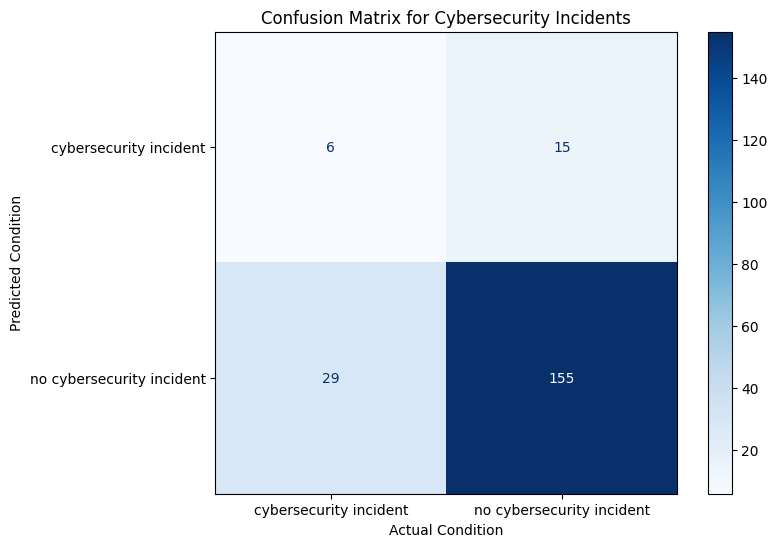

Accuracy: 0.79
Precision: 0.29
Recall: 0.17
F1-score: 0.21


(0.7854, 0.2857, 0.1714, 0.2143)

In [71]:
gbm = GradientBoostingClassifier(
              random_state=random_variable,
              n_estimators=500
              )

gbm.fit(X_train, y_train)

predictions_gbm_w_dummies = gbm.predict(X_test)

evaluate_model(y_test, predictions_gbm_w_dummies)
